# 🧠 Machine Learning *davvero*: dalla softmax alle CNN, solo con NumPy
Percorso di **6 esercizi progressivi**: ogni esercizio riusa i pezzi costruiti nei precedenti. Alla fine avrai scritto da zero una CNN con backprop, e capirai perché funziona.

**Legenda**
- 📐 **Derivazione**: da fare *su carta, prima di toccare il codice*. Il codice ti dirà se hai ragione (gradient check numerico).
- ✍️ **Da completare**: celle con `raise NotImplementedError` → sostituiscile.
- 📊 **Prefatto**: grafici/esperimenti già pronti, tu li esegui e *interpreti*.
- 🎬 **Video**: come trasformare l'esercizio in un episodio.

| # | Tema | Cosa costruisci | Concetto "che resta impresso" |
|---|---|---|---|
| 1 | Softmax + cross-entropy | loss stabile + gradiente, classificatore lineare | il gradiente è semplicemente `p − y` |
| 2 | Backprop modulare, MLP | `Linear`, `ReLU`, `Sequential`, gradient check | senza non-linearità la profondità è inutile |
| 3 | Funzioni di attivazione & flusso del gradiente | `Sigmoid`, `Tanh`, esperimenti di init | i gradienti svaniscono *moltiplicandosi* |
| 4 | Convoluzione | `Conv2D` forward/backward con stride e padding | pesi condivisi = equivarianza + pochi parametri |
| 5 | Pooling e CNN completa | `MaxPool2`, `Flatten`, CNN su cifre | max-pool = router del gradiente |
| 6 | Receptive field & Grad-CAM | RF misurato con la backprop, mappe di salienza | "dove guarda" la rete = un gradiente |

**Convenzione importante:** nelle slide $s = Wx$ (vettori colonna). Qui lavoriamo con **batch a righe**: $X\in\mathbb{R}^{N\times D}$, $S = XW + b$. Le formule cambiano forma: ri-derivarle con le dimensioni giuste fa parte dell'esercizio.

> Serve `scikit-learn` solo per il dataset delle cifre (`pip install scikit-learn`).

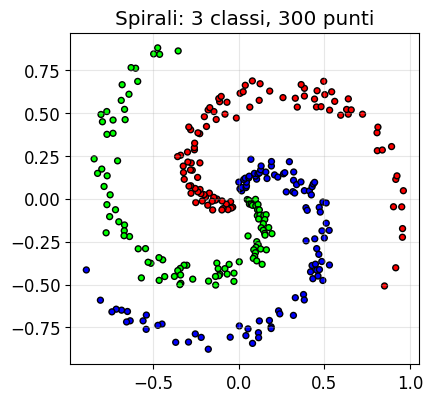

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)
plt.rcParams.update({"figure.figsize": (6, 4), "axes.grid": True, "grid.alpha": .3, "font.size": 12})

# ---------- Gradient check numerico (differenze centrali) ----------
def num_grad(f, x, h=1e-5):
    """Gradiente numerico di f() (scalare) rispetto all'array x, modificato *in place* e poi ripristinato."""
    g = np.zeros_like(x, dtype=float)
    it = np.nditer(x, flags=["multi_index"])
    while not it.finished:
        i = it.multi_index
        old = x[i]
        x[i] = old + h; fp = f()
        x[i] = old - h; fm = f()
        x[i] = old
        g[i] = (fp - fm) / (2 * h)
        it.iternext()
    return g

def rel_err(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return np.max(np.abs(a - b) / np.maximum(1e-8, np.abs(a) + np.abs(b)))

def check(name, a, b, tol=1e-6):
    e = rel_err(a, b)
    print(f"{'✅' if e < tol else '❌'} {name:<30} errore relativo = {e:.2e}")
    return e < tol

# ---------- Dataset giocattolo: spirali ----------
def make_spiral(n=100, K=3, noise=0.2, seed=0):
    r = np.random.RandomState(seed)
    X = np.zeros((n * K, 2)); y = np.zeros(n * K, dtype=int)
    for k in range(K):
        ix = slice(n * k, n * (k + 1))
        rad = np.linspace(0.05, 1, n)
        t = np.linspace(k * 4, (k + 1) * 4, n) + r.randn(n) * noise
        X[ix] = np.c_[rad * np.sin(t), rad * np.cos(t)]
        y[ix] = k
    return X, y

def plot_boundary(predict, X, y, ax=None, title=""):
    ax = ax or plt.gca()
    xx, yy = np.meshgrid(np.linspace(-1.2, 1.2, 200), np.linspace(-1.2, 1.2, 200))
    Z = predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    K = int(y.max()) + 1
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="brg", levels=np.arange(K + 1) - 0.5)
    ax.scatter(X[:, 0], X[:, 1], c=y, s=14, cmap="brg", edgecolor="k", linewidth=.3)
    ax.set_title(title); ax.set_aspect("equal"); ax.grid(False)

X, y = make_spiral(100, 3)
plt.figure(figsize=(4.5, 4.5)); plt.scatter(X[:, 0], X[:, 1], c=y, cmap="brg", edgecolor="k", s=18)
plt.title("Spirali: 3 classi, 300 punti"); plt.gca().set_aspect("equal"); plt.show()

---
# Esercizio 1 — Softmax e cross-entropy: perché il gradiente è `p − y`
**Obiettivo:** costruire la loss di classificazione *numericamente stabile*, derivarne il gradiente a mano, e usarla per addestrare un classificatore lineare. Poi vedere *dove* un classificatore lineare fallisce.

### 📐 Derivazioni (su carta, in quest'ordine)
Sia $s\in\mathbb{R}^C$ il vettore dei logit, $p_k = e^{s_k}/\sum_j e^{s_j}$, $L = -\log p_y$.

1. Dimostra che $\text{softmax}(s)=\text{softmax}(s-c)$ per ogni costante $c$. Perché scegliere $c=\max_j s_j$ evita l'overflow *senza* cambiare il risultato?
2. Riscrivi $L = -s_y + \log\sum_j e^{s_j}$ (log-sum-exp). Perché questa forma è quella da implementare?
3. Calcola $\partial L/\partial s_k$ **separando i casi** $k=y$ e $k\neq y$. Arriva a un'unica espressione vettoriale con il vettore one-hot $e_y$. Quanto vale la somma delle componenti del gradiente? Perché *deve* valere così (ricorda il punto 1)?
4. **Batch.** $S = XW+b$, con $X\in\mathbb{R}^{N\times D}$, $W\in\mathbb{R}^{D\times C}$, $L=\frac1N\sum_i L_i$. Ricava $\partial L/\partial S$, $\partial L/\partial W$, $\partial L/\partial b$ **controllando le dimensioni** di ogni passaggio.
5. Con $W=0$ quanto vale la loss con $C$ classi? (È il tuo primo *sanity check* quando addestri qualsiasi rete.)
6. Aggiungi $\lambda\sum W_{kl}^2$: come cambia $\partial L/\partial W$?

<details><summary>💡 Suggerimento sul punto 3</summary>
Derivi $-s_y$ e poi $\log Z$ con $Z=\sum_j e^{s_j}$: $\partial_{s_k}\log Z = e^{s_k}/Z$. Riconosci qualcosa?
</details>

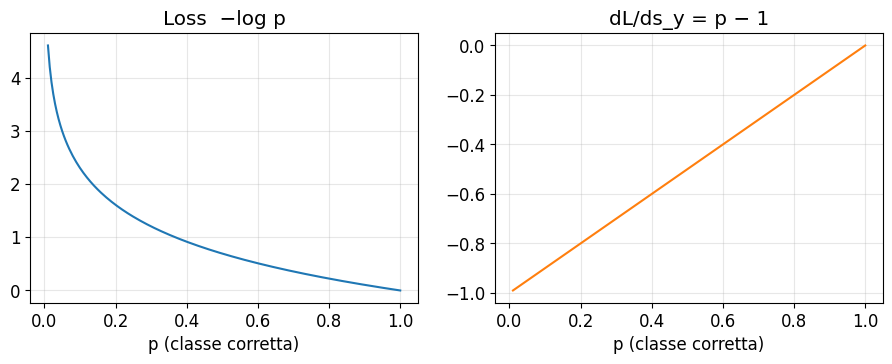

exp(1000) = inf -> softmax naive: [nan  0.  0.]


In [2]:
# 📊 PREFATTO — cosa stai per ottimizzare
p = np.linspace(0.01, 1, 200)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(p, -np.log(p)); ax[0].set_xlabel("p (classe corretta)"); ax[0].set_title("Loss  −log p")
ax[1].plot(p, p - 1, color="C1"); ax[1].set_xlabel("p (classe corretta)"); ax[1].set_title("dL/ds_y = p − 1")
plt.show()

# Perché serve la stabilità numerica:
with np.errstate(all="ignore"):
    s = np.array([1000., 0., 0.])
    print("exp(1000) =", np.exp(s[0]), "-> softmax naive:", np.exp(s) / np.exp(s).sum())

In [ ]:
# ✍️ DA COMPLETARE — loss + gradiente rispetto ai logit
def softmax_ce(S, y):
    """S: (N,C) logit; y: (N,) etichette intere.
    Ritorna (loss media, dS) con dS = dL/dS di forma (N,C)."""
    N = S.shape[0]
    # TODO 1: sottrai il massimo di ogni riga (stabilità)
    # TODO 2: log-softmax tramite log-sum-exp (mai exp/ somma-exp senza log)
    # TODO 3: loss media = -media di log p della classe corretta
    # TODO 4: dS = (p - e_y)/N     (usa l'indicizzazione  dS[np.arange(N), y])
    raise NotImplementedError("completa softmax_ce")

S = np.random.randn(5, 4); yy = np.random.randint(0, 4, 5)
loss, dS = softmax_ce(S, yy)
check("dL/dS vs numerico", dS, num_grad(lambda: softmax_ce(S, yy)[0], S))
check("loss(S=0) = log C", softmax_ce(np.zeros((10, 5)), np.zeros(10, int))[0], np.log(5))
check("stabile con logit 1000", softmax_ce(np.array([[1000., 0, 0]]), np.array([0]))[0], 0.0, tol=1e-9)
print("somma delle componenti del gradiente per riga (deve essere ~0):", np.abs(dS.sum(1)).max())

In [ ]:
# ✍️ DA COMPLETARE — gradienti del classificatore lineare S = XW + b (con L2)
def linear_grads(X, y, W, b, lam=0.0):
    S = X @ W + b
    loss, dS = softmax_ce(S, y)
    # TODO: aggiungi lam*||W||^2 alla loss e calcola dW, db (dalle tue derivazioni del punto 4 e 6)
    raise NotImplementedError("completa linear_grads")

Xs, ys = np.random.randn(6, 3), np.random.randint(0, 4, 6)
Ws, bs = np.random.randn(3, 4) * .5, np.random.randn(4) * .5
_, dW, db = linear_grads(Xs, ys, Ws, bs, lam=0.1)
check("dL/dW", dW, num_grad(lambda: linear_grads(Xs, ys, Ws, bs, 0.1)[0], Ws))
check("dL/db", db, num_grad(lambda: linear_grads(Xs, ys, Ws, bs, 0.1)[0], bs))

In [ ]:
# 📊 PREFATTO — addestriamo con SGD e guardiamo cosa succede
def train_linear(X, y, lr=1.0, lam=1e-3, epochs=400):
    W = 0.01 * np.random.randn(X.shape[1], int(y.max()) + 1); b = np.zeros(W.shape[1]); hist = []
    for _ in range(epochs):
        loss, dW, db = linear_grads(X, y, W, b, lam)
        W -= lr * dW; b -= lr * db; hist.append(loss)
    return W, b, hist

X, y = make_spiral(100, 3)
W, b, hist = train_linear(X, y)
pred = lambda Z: np.argmax(Z @ W + b, axis=1)
acc = (pred(X) == y).mean()
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
plot_boundary(pred, X, y, ax[0], f"Softmax lineare — accuracy {acc:.0%}")
ax[1].plot(hist); ax[1].axhline(np.log(3), ls="--", c="gray"); ax[1].set_title("loss (linea = log 3)"); ax[1].set_xlabel("iterazione")
plt.show()

# Mini-esercizio L2 (slide): stesso score, regolarizzazione diversa
x = np.ones(4); w1 = np.array([1, 0, 0, 0.]); w2 = np.full(4, .25)
for n, w in [("w1", w1), ("w2", w2)]:
    print(f"{n}: score={w @ x:.2f}  L2={np.sum(w**2):.3f}  L1={np.abs(w).sum():.3f}")

**❓ Domande (rispondi per iscritto):**
(a) Perché la loss non scende sotto ~0.8–0.9 qualunque sia il learning rate? (b) Cosa cambia nei punti 3–4 se usi $\lambda$ molto grande? (c) Perché L2 preferisce $w_2$ e L1 è indifferente?

### 🎬 Video 1 — *"Il gradiente più elegante del deep learning"*
- **Hook (0:00):** "Ogni rete che classifica usa questa formula. Ha un solo termine: `p − y`. Perché?"
- **Scena 1:** mostra il grafico prefatto di $-\log p$: "una predizione sicura e sbagliata costa tantissimo".
- **Scena 2:** la derivazione a mano del punto 3 (lavagna/Manim): i due casi $k=y$ e $k\neq y$ che collassano in un'unica riga.
- **Scena 3:** `exp(1000) = inf` → il trucco del massimo. Fai vedere la softmax "naive" restituire `nan`.
- **Scena 4:** il decision boundary lineare sulle spirali che fallisce. *Cliffhanger:* "come si fa a piegare quel confine?" → Video 2.
- **Take-away:** il gradiente è "quanto la rete sbaglia", componente per componente, e somma a zero.

---
# Esercizio 2 — Backpropagation modulare e primo MLP
**Obiettivo:** costruire dei *mattoncini* (`Linear`, `ReLU`) con `forward`/`backward`, assemblarli in un `Sequential`, e verificare *l'intera* backprop con il gradient check. Poi capire sperimentalmente perché la non-linearità è indispensabile.

### 📐 Derivazioni
Ogni nodo riceve il gradiente **upstream** $\partial L/\partial Y$ e restituisce quello **downstream** $\partial L/\partial X$ (e i gradienti dei suoi parametri). Regola della catena = *upstream × locale*.

1. **Linear:** $Y=XW+b$ con $X\in\mathbb{R}^{N\times D},\,W\in\mathbb{R}^{D\times M}$. Parti da $y_{n,m}=\sum_d x_{n,d}w_{d,m}+b_m$ e ricava, *per indici*, $\partial L/\partial x_{n,d}$, $\partial L/\partial w_{d,m}$, $\partial L/\partial b_m$. Poi riscrivi in forma matriciale. Controlla che le dimensioni combacino (è "l'unico modo possibile", dicono le slide: verifica che sia vero).
2. **ReLU:** scrivi la Jacobiana di $y=\max(0,x)$ per $x\in\mathbb{R}^4$. Perché è diagonale? Perché **non** costruirla mai esplicitamente? Qual è la formula implicita (elementwise)?
3. **Non-linearità:** dimostra che $W_2(W_1x)=W'x$. Quindi cosa succede a una rete di 10 strati lineari?
4. Conta i parametri di una rete $2\to64\to3$ con bias.
5. Perché in `forward` dobbiamo *salvare* qualcosa (`self.X`) per il `backward`? Cosa serve esattamente a `Linear` e a `ReLU`?

In [ ]:
# ✍️ DA COMPLETARE — i mattoncini
class Linear:
    def __init__(self, din, dout, scale=None):
        scale = np.sqrt(2.0 / din) if scale is None else scale      # (in Es.3 capirai da dove viene)
        self.P = {"W": scale * np.random.randn(din, dout), "b": np.zeros(dout)}   # parametri
        self.G = {}                                                               # gradienti
    def forward(self, X):
        self.X = X
        return X @ self.P["W"] + self.P["b"]
    def backward(self, dY):
        # TODO: riempi self.G["W"], self.G["b"] e ritorna dX
        raise NotImplementedError("Linear.backward")

class ReLU:
    def __init__(self): self.P, self.G = {}, {}
    def forward(self, X):
        self.X = X
        raise NotImplementedError("ReLU.forward")
    def backward(self, dY):
        # TODO: moltiplicazione IMPLICITA con la Jacobiana (mai matrici NxN)
        raise NotImplementedError("ReLU.backward")

class Identity:     # "nessuna attivazione" (per l'esperimento finale)
    def __init__(self): self.P, self.G = {}, {}
    def forward(self, X): return X
    def backward(self, dY): return dY

# ----- PREFATTO: contenitore, training loop, gradient check dell'intero modello -----
class Sequential:
    def __init__(self, layers): self.layers = layers
    def forward(self, X):
        for l in self.layers: X = l.forward(X)
        return X
    def backward(self, d):
        for l in reversed(self.layers): d = l.backward(d)
        return d

def count_params(model): return sum(v.size for l in model.layers for v in l.P.values())

def train(model, X, y, lr=0.5, epochs=1000, lam=0.0):
    hist = []
    for _ in range(epochs):
        loss, dS = softmax_ce(model.forward(X), y)
        model.backward(dS)
        for l in model.layers:
            for k in l.P:
                l.P[k] -= lr * (l.G[k] + (2 * lam * l.P[k] if k == "W" else 0))
        hist.append(loss)
    return hist

def gradcheck_model(model, X, y, tol=1e-5):
    f = lambda: softmax_ce(model.forward(X), y)[0]
    model.backward(softmax_ce(model.forward(X), y)[1])
    ok = True
    for i, l in enumerate(model.layers):
        for k in l.P:
            e = rel_err(l.G[k], num_grad(f, l.P[k]))
            print(f"{'✅' if e < tol else '❌'} layer {i} {type(l).__name__}.{k}: errore relativo = {e:.2e}")
            ok &= e < tol
    return ok

tiny = Sequential([Linear(2, 5), ReLU(), Linear(5, 3)])
gradcheck_model(tiny, np.random.randn(4, 2), np.random.randint(0, 3, 4))

In [ ]:
# 📊 PREFATTO — MLP vs lineare vs "MLP senza attivazione" vs MLP con L2 forte
X, y = make_spiral(100, 3)
def make_mlp(h=64, act=ReLU): return Sequential([Linear(2, h), act(), Linear(h, 3)])

configs = [("MLP + ReLU", ReLU, 0.0), ("MLP SENZA attivazione", Identity, 0.0), ("MLP + ReLU, L2 forte (λ=0.05)", ReLU, 0.05)]
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
for a, (name, act, lam) in zip(ax, configs):
    np.random.seed(1); m = make_mlp(64, act); hist = train(m, X, y, lr=0.5, epochs=1500, lam=lam)
    acc = (m.forward(X).argmax(1) == y).mean()
    plot_boundary(lambda Z: m.forward(Z).argmax(1), X, y, a, f"{name}\nacc {acc:.0%}, loss {hist[-1]:.2f}")
plt.show()
print("parametri 2→64→3:", count_params(make_mlp()))

**❓ Domande:** (a) Perché il modello "senza attivazione" si comporta come il classificatore dell'Es.1, pur avendo 64 neuroni nascosti? Collegalo alla derivazione 3. (b) Cosa fa L2 forte al confine di decisione? Perché "preferisci modelli grandi, fortemente regolarizzati"?

### 🎬 Video 2 — *"Perché una rete profonda senza ReLU non serve a niente"*
- **Hook:** "Ho una rete con 64 neuroni e fa schifo quanto una retta. Indovina perché?"
- **Scena 1:** la dimostrazione $W_2W_1=W'$ (3 righe, animata).
- **Scena 2:** costruisci i mattoncini *dal vivo* come "scatole" con frecce forward (blu) e backward (rosse); metti in scena il concetto upstream × locale.
- **Scena 3:** il **gradient check** come "il momento della verità": errore `1e-9` ✅ vs un bug volutamente inserito ❌ (ottimo per la retention).
- **Scena 4:** i 3 decision boundary affiancati (prefatto), L2 che "stira" il confine.
- **Take-away:** una rete è un grafo di piccoli pezzi *stupidi*; la backprop è solo la catena.

---
# Esercizio 3 — Funzioni di attivazione e flusso del gradiente
**Obiettivo:** implementare `Sigmoid` e `Tanh`, poi *misurare* cosa succede ai gradienti attraversando 10 strati con diverse attivazioni e inizializzazioni. Il vanishing gradient lo *vedi con i tuoi occhi*.

### 📐 Derivazioni
1. Dimostra $\sigma'(x)=\sigma(x)(1-\sigma(x))$ e che $\max\sigma'=1/4$. Dimostra $\tanh x = 2\sigma(2x)-1$ e deduci $\tanh'(x)=1-\tanh^2(x)$. Perché conviene riusare l'*output* della forward nel backward?
2. **Vanishing gradient.** In una catena di $L$ strati il gradiente verso il primo strato contiene un prodotto $\prod_\ell \sigma'(a_\ell)\,W_\ell$. Con solo sigmoidi, dai un *upper bound* del fattore dovuto alle attivazioni dopo $L$ strati. Cosa cambia con ReLU?
3. **Varianza e inizializzazione.** Sia $y=\sum_{i=1}^{n}w_ix_i$ con $w_i, x_i$ indipendenti a media zero. Mostra che $\mathrm{Var}(y)=n\,\mathrm{Var}(w)\,\mathbb{E}[x^2]$. Quale $\mathrm{Var}(w)$ mantiene la varianza costante da uno strato al successivo se $x$ è l'ingresso grezzo (→ **Xavier**)? Se invece $x=\max(0,a)$ con $a$ simmetrico, mostra che $\mathbb{E}[x^2]=\tfrac12\mathrm{Var}(a)$ e deduci il fattore per ReLU (→ **He**, il `sqrt(2/din)` che usavamo sopra).
4. **ReLU morta:** in quali condizioni il gradiente di un neurone ReLU è zero *per sempre* su tutto il dataset? Cosa risolve Leaky ReLU?

In [ ]:
# ✍️ DA COMPLETARE — due nuove attivazioni
class Sigmoid:
    def __init__(self): self.P, self.G = {}, {}
    def forward(self, X):
        # TODO: sigma(x); salva in self.out ciò che ti serve per il backward
        raise NotImplementedError("Sigmoid.forward")
    def backward(self, dY):
        raise NotImplementedError("Sigmoid.backward")

class Tanh:
    def __init__(self): self.P, self.G = {}, {}
    def forward(self, X):
        raise NotImplementedError("Tanh.forward")
    def backward(self, dY):
        raise NotImplementedError("Tanh.backward")

for A in (Sigmoid, Tanh):
    m = Sequential([Linear(3, 4), A(), Linear(4, 3)])
    print(A.__name__); gradcheck_model(m, np.random.randn(5, 3), np.random.randint(0, 3, 5))

In [ ]:
# 📊 PREFATTO — funzioni e derivate (la derivata è ottenuta dalla TUA backward con upstream = 1)
xs = np.linspace(-6, 6, 400)[:, None]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for A in (Sigmoid, Tanh, ReLU):
    a = A(); ax[0].plot(xs, a.forward(xs), label=A.__name__); ax[1].plot(xs, a.backward(np.ones_like(xs)), label=A.__name__)
ax[0].set_title("attivazione"); ax[1].set_title("derivata (flusso del gradiente)"); ax[0].legend(); ax[1].set_ylim(-.1, 1.2); plt.show()

In [ ]:
# 📊 PREFATTO — esperimento: norma del gradiente per ognuno dei 10 strati nascosti
def build_deep(act, depth, width, init, din, C=3):
    layers, d = [], din
    for _ in range(depth):
        scale = {"piccola (0.01)": 0.01, "Xavier": np.sqrt(1 / d), "He": np.sqrt(2 / d)}[init]
        layers += [Linear(d, width, scale), act()]; d = width
    return Sequential(layers + [Linear(d, C, np.sqrt(1 / d))])

def gradient_flow(act, init, depth=10, width=50, N=256):
    rs = np.random.RandomState(0); Xr, yr = rs.randn(N, width), rs.randint(0, 3, N)
    np.random.seed(0); m = build_deep(act, depth, width, init, width)
    _, dS = softmax_ce(m.forward(Xr), yr); m.backward(dS)
    return [np.linalg.norm(l.G["W"]) for l in m.layers if isinstance(l, Linear)][:-1]

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for a, init in zip(ax, ["piccola (0.01)", "Xavier", "He"]):
    for A in (Sigmoid, Tanh, ReLU):
        a.semilogy(range(1, 11), gradient_flow(A, init), "o-", label=A.__name__)
    a.set_title(f"init {init}"); a.set_xlabel("strato (1 = ingresso → 10 = vicino alla loss)")
ax[0].set_ylabel("‖dL/dW‖"); ax[0].legend(); plt.show()

In [ ]:
# 📊 PREFATTO — conseguenze sull'apprendimento (rete a 6 strati nascosti sulle spirali)
X, y = make_spiral(100, 3)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for A, init in [(Sigmoid, "Xavier"), (Tanh, "Xavier"), (ReLU, "He")]:
    np.random.seed(3); m = build_deep(A, 6, 32, init, 2)
    h = train(m, X, y, lr=0.1, epochs=2000)
    ax[0].plot(h, label=f"{A.__name__} ({init})")
    ax[1].bar(A.__name__, (m.forward(X).argmax(1) == y).mean())
ax[0].set_title("loss di training"); ax[0].legend(); ax[1].set_title("accuracy finale"); plt.show()

# Neuroni ReLU morti: learning rate enorme
for lr in (0.1, 1.5):
    np.random.seed(3); m = build_deep(ReLU, 6, 32, "He", 2); train(m, X, y, lr=lr, epochs=300)
    h = X; dead = []
    for l in m.layers:
        h = l.forward(h)
        if isinstance(l, ReLU): dead.append(np.mean((h > 0).sum(0) == 0))
    print(f"lr={lr}: frazione media di neuroni ReLU morti (mai attivi) = {np.mean(dead):.0%}")

**❓ Domande:** (a) Nel grafico 1 perché con init piccola *tutte* le attivazioni collassano, anche ReLU? Collegalo a $\mathrm{Var}(y)=n\mathrm{Var}(w)\mathbb{E}[x^2]$. (b) Perché Xavier va bene per tanh ma He serve per ReLU? (c) Cosa ti dice la frazione di ReLU morte?

### 🎬 Video 3 — *"Perché le reti profonde non imparavano (fino al 2012)"*
- **Hook:** "Nel 1990 sapevamo fare reti profonde. Non imparavano. Il colpevole è un numero: 0.25."
- **Scena 1:** la sigmoide e la sua derivata (grafico prefatto): massimo 0.25. "Moltiplica 0.25 per sé stesso 10 volte."
- **Scena 2:** il grafico semilog della norma del gradiente: le curve che precipitano (sigmoid) vs quella piatta (ReLU+He) — *il visual centrale del video*.
- **Scena 3:** derivazione della varianza → Xavier e He, "da dove viene quel `sqrt(2/n)`".
- **Scena 4:** i neuroni morti (learning rate alto).
- **Take-away:** ReLU + buona inizializzazione = il gradiente arriva fino in fondo.

---
# Esercizio 4 — La convoluzione: forward, backward, e perché risparmia parametri
**Obiettivo:** implementare un layer `Conv2D` completo (batch, canali, **stride**, **padding**) con la sua backprop, validarlo contro una versione lenta e col gradient check, ed *evidenziare* equivarianza alla traslazione e risparmio di parametri.

### 📐 Derivazioni
Convenzione DL (cross-correlazione): $y[n,o,i,j]=b_o+\sum_{c,k,l}W[o,c,k,l]\;x_p[n,c,\,iS+k,\,jS+l]$, dove $x_p$ è l'input con padding $P$.

1. **Dimensione dell'output.** Ricava $W_{out}=\lfloor (W_{in}+2P-F)/S\rfloor+1$ contando le posizioni valide del filtro. Verifica: $(32,F{=}5,P{=}2,S{=}1)\to32$; $(227,11,0,4)\to55$; $(224,2,0,2)\to112$.
2. **Convoluzione vs cross-correlazione.** Calcola a mano il pixel centrale di $I=\begin{pmatrix}8&5&2\\7&5&3\\9&4&1\end{pmatrix}$ con $g=\begin{pmatrix}-1&0&1\\-1&0&1\\-1&0&1\end{pmatrix}$ nei due casi (con e senza ribaltare $g$). Che relazione c'è? Perché a una rete che *apprende* il kernel non importa?
3. **Parametri.** Immagine $1000\times1000$, $10^6$ neuroni nascosti. Conta i pesi: (a) fully connected; (b) localmente connesso con finestra $10\times10$; (c) convoluzionale con 100 filtri $10\times10$ (pesi condivisi). Formula generale conv: $C_{out}(C_{in}F^2+1)$.
4. **Backward** (il cuore dell'esercizio). Per $y[n,o,i,j]$ sopra, ricava:
   - $\partial L/\partial W[o,c,k,l]$ → è una somma su *tutte le posizioni* in cui il peso è stato usato. Perché ricorda il **copy gate**?
   - $\partial L/\partial x_p[n,c,p,q]$ → quali $(o,i,j,k,l)$ contribuiscono? 
   - $\partial L/\partial b_o$.
   - Come si ottiene $\partial L/\partial x$ dal gradiente sul tensore *con padding*?
5. **Trucco implementativo.** Invece di 6 cicli, ciclare *solo* sugli offset $(k,l)$ del filtro: per ognuno la fetta `Xp[:, :, k:k+S*Ho:S, l:l+S*Wo:S]` ha forma $(N,C_{in},H_o,W_o)$. Scrivi, per un singolo $(k,l)$, la forward e i due contributi di backward come `einsum`.

<details><summary>💡 Suggerimento sul punto 5</summary>
Forward: <code>out += einsum("nchw,oc->nohw", patch, W[:,:,k,l])</code>. Nel backward gli indici dell'einsum sono gli <i>stessi</i>, cambia quale operando è l'output.
</details>

In [ ]:
# ✍️ DA COMPLETARE — utilità sulle dimensioni e sui parametri
def conv_out_size(w_in, F, P=0, S=1):
    raise NotImplementedError

def params_fc(n_in, n_hidden):        # senza bias
    raise NotImplementedError
def params_local(F, n_hidden):        # senza bias, un filtro FxF diverso per ogni neurone
    raise NotImplementedError
def params_conv(c_in, c_out, F):      # con bias
    raise NotImplementedError

assert conv_out_size(32, 5, 2, 1) == 32 and conv_out_size(227, 11, 0, 4) == 55 and conv_out_size(224, 2, 0, 2) == 112
print(f"fully connected: {params_fc(10**6, 10**6):.0e}   locale: {params_local(10, 10**6):.0e}   conv: {params_conv(1, 100, 10)}")
assert params_conv(3, 10, 5) == 760
print("✅ dimensioni e parametri OK")

In [ ]:
# ✍️ DA COMPLETARE — Conv2D vettorizzata sui batch (cicla solo sugli offset del filtro)
class Conv2D:
    def __init__(self, cin, cout, F, stride=1, pad=0):
        self.S, self.Pd, self.F = stride, pad, F
        self.P = {"W": np.sqrt(2.0 / (cin * F * F)) * np.random.randn(cout, cin, F, F), "b": np.zeros(cout)}
        self.G = {}

    def forward(self, X):
        S, Pd, F = self.S, self.Pd, self.F
        W, b = self.P["W"], self.P["b"]
        N, Cin, H, Wd = X.shape
        Xp = np.pad(X, ((0, 0), (0, 0), (Pd, Pd), (Pd, Pd)))
        Ho, Wo = conv_out_size(H, F, Pd, S), conv_out_size(Wd, F, Pd, S)
        self.cache = (X.shape, Xp, Ho, Wo)
        # TODO: out (N,Cout,Ho,Wo) = somma sugli offset (k,l) dei contributi + bias
        raise NotImplementedError("Conv2D.forward")

    def backward(self, dY):
        S, Pd, F = self.S, self.Pd, self.F
        W = self.P["W"]
        xshape, Xp, Ho, Wo = self.cache
        # TODO: riempi self.G["W"], self.G["b"], e ritorna dX (senza padding!) di forma xshape
        raise NotImplementedError("Conv2D.backward")

In [ ]:
# 📊 PREFATTO — validazione: (1) contro la versione lenta a 4 cicli, (2) gradient check, (3) l'esempio delle slide
def conv_naive(X, W, b, S=1, P=0):
    N, Cin, H, Wd = X.shape; Co, _, F, _ = W.shape
    Xp = np.pad(X, ((0, 0), (0, 0), (P, P), (P, P)))
    Ho, Wo = (H + 2 * P - F) // S + 1, (Wd + 2 * P - F) // S + 1
    out = np.zeros((N, Co, Ho, Wo))
    for n in range(N):
        for o in range(Co):
            for i in range(Ho):
                for j in range(Wo):
                    out[n, o, i, j] = np.sum(Xp[n, :, i*S:i*S+F, j*S:j*S+F] * W[o]) + b[o]
    return out

for S_, P_ in [(1, 0), (1, 2), (2, 1)]:
    c = Conv2D(3, 4, 5 if P_ == 2 else 3, S_, P_); c.P["b"] = np.random.randn(4)
    Xt = np.random.randn(2, 3, 9, 9)
    check(f"forward vs naive (S={S_},P={P_})", c.forward(Xt), conv_naive(Xt, c.P["W"], c.P["b"], S_, P_))

# gradient check (stride 2 + padding 1 = il caso più scomodo)
c = Conv2D(2, 3, 3, stride=2, pad=1); Xt = np.random.randn(2, 2, 7, 7); R = np.random.randn(2, 3, 4, 4)
f = lambda: np.sum(c.forward(Xt) * R)            # loss finta: upstream = R
c.forward(Xt); dX = c.backward(R)
check("dL/dX", dX, num_grad(f, Xt)); check("dL/dW", c.G["W"], num_grad(f, c.P["W"])); check("dL/db", c.G["b"], num_grad(f, c.P["b"]))

# esempio delle slide: convoluzione VERA = cross-correlazione con kernel ribaltato
I = np.array([[8, 5, 2], [7, 5, 3], [9, 4, 1]], float); g = np.array([[-1, 0, 1]] * 3, float)
c = Conv2D(1, 1, 3, pad=1)
c.P["W"][0, 0] = g[::-1, ::-1]; true_conv = c.forward(I[None, None])[0, 0]
c.P["W"][0, 0] = g;             xcorr = c.forward(I[None, None])[0, 0]
print(true_conv); assert np.allclose(true_conv, [[-10, 10, 10], [-14, 18, 14], [-9, 12, 9]]) and np.allclose(xcorr, -true_conv)
print("✅ Esempio delle slide riprodotto; cross-correlazione = convoluzione con segno invertito qui")

In [ ]:
# 📊 PREFATTO — la convoluzione come "rilevatore": filtri di Sobel su un'immagine sintetica
img = np.zeros((32, 32)); img[8:24, 8:24] = 1.0
yy, xx = np.mgrid[:32, :32]; img[(xx - 16) ** 2 + (yy - 16) ** 2 < 25] = 0.4
Kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float)
c = Conv2D(1, 3, 3, pad=1); c.P["W"][0, 0], c.P["W"][1, 0], c.P["W"][2, 0] = Kx, Kx.T, np.ones((3, 3)) / 9
maps = c.forward(img[None, None])[0]
fig, ax = plt.subplots(1, 4, figsize=(15, 3.8))
for a, m, t in zip(ax, [img, *maps], ["immagine", "Sobel x (bordi verticali)", "Sobel y (bordi orizzontali)", "media 3x3 (blur)"]):
    a.imshow(m, cmap="gray"); a.set_title(t); a.axis("off")
plt.show()

In [ ]:
# ✍️ DA COMPLETARE — equivarianza alla traslazione:  conv(shift(x)) = shift(conv(x))
def shift_equivariance_error(conv, img, dy, dx):
    """Massima differenza assoluta tra conv(shift(img)) e shift(conv(img)). shift = np.roll (l'immagine ha bordo nero)."""
    # TODO: applica lo shift all'ingresso e confronta con lo shift dell'uscita
    raise NotImplementedError

print("errore equivarianza (conv):", shift_equivariance_error(c, img, 3, 5))

**❓ Domande:** (a) Perché l'errore è ~0? Quale proprietà dei *pesi condivisi* lo garantisce? Cosa succederebbe con un layer localmente connesso (pesi diversi per ogni posizione)? (b) Cosa cambierebbe vicino ai bordi con `np.roll` se l'immagine non avesse bordo nero? (c) Il gradiente di $W$ è una *somma su tutte le posizioni*: perché questo lo rende "più stabile" di quello di un peso usato una sola volta?

### 🎬 Video 4 — *"La convoluzione in 10 minuti: perché una CNN ha 100 milioni di parametri in meno"*
- **Hook:** "Un'immagine 1000×1000 con un layer denso: **un trilione** di parametri. Con una convoluzione: **diecimila**."
- **Scena 1:** la tabella FC / locale / conv (esercizio parametri) animata come barre su scala log.
- **Scena 2:** il kernel che "scorre" sull'immagine, con calcolo a mano del pixel centrale (+18 / −18 → la questione convoluzione vs cross-correlazione, come "il piccolo segreto dei framework").
- **Scena 3:** Sobel che fa apparire i bordi (prefatto): "i primi filtri di una CNN sono questi".
- **Scena 4:** la backprop: "il gradiente del kernel è la somma su tutte le posizioni" (animazione *copy gate*).
- **Scena 5:** il test di equivarianza (errore `0.0`): *la proprietà matematica che motiva le CNN*.
- **Take-away:** località + condivisione dei pesi = pochi parametri + equivarianza gratis.

---
# Esercizio 5 — Max pooling e CNN completa (cifre scritte a mano)
**Obiettivo:** completare i mattoncini mancanti (`MaxPool2`, `Flatten`), assemblare una CNN, addestrarla e *confrontarla con un MLP* con lo stesso numero di parametri, anche sotto traslazioni dell'input.

### 📐 Derivazioni
1. **Max pool $2\times2$, stride 2.** Per $y=\max(a,b,c,d)$ calcola $\partial y/\partial a$. Quindi la backward del pooling è un... *router*: cosa riceve ogni elemento della finestra? Come tratti i **pareggi** (due elementi uguali al massimo)? (Pensa a cosa darebbe il gradiente numerico.)
2. Perché il pooling non ha parametri? Perché agisce sui canali *indipendentemente*? Che forma ha l'output di $(N,C,H,W)$?
3. **Traccia le dimensioni** (batch ignorato): $1\times8\times8\to$ Conv(8 filtri $3\times3$, pad 1) $\to$ ReLU $\to$ MaxPool2 $\to$ Flatten $\to$ Linear(?, 10). Qual è il `?`. Quanti parametri totali?
4. **Invarianza vs equivarianza:** la conv è equivariante alla traslazione. Il pooling aggiunge *invarianza locale*: perché, se sposto l'input di 1 pixel *dentro* la finestra, l'uscita spesso non cambia? Perché l'invarianza è solo *approssimata*?

<details><summary>💡 Suggerimento pooling</summary>
<code>X.reshape(N,C,H//2,2,W//2,2)</code> trasforma ogni finestra 2×2 in due assi (3 e 5): il massimo su <code>axis=(3,5)</code> è il pooling. Per la backward costruisci una <i>maschera</i> con <code>Xr == out[:,:,:,None,:,None]</code> e dividila per il numero di massimi (pareggi).
</details>

In [ ]:
# ✍️ DA COMPLETARE
class MaxPool2:
    def __init__(self): self.P, self.G = {}, {}
    def forward(self, X):
        N, C, H, W = X.shape
        self.shape = X.shape
        # TODO: out (N,C,H/2,W/2) e salva ciò che serve alla backward (una "maschera")
        raise NotImplementedError("MaxPool2.forward")
    def backward(self, dY):
        # TODO: instrada il gradiente solo verso il massimo
        raise NotImplementedError("MaxPool2.backward")

class Flatten:
    def __init__(self): self.P, self.G = {}, {}
    def forward(self, X):
        self.shape = X.shape
        raise NotImplementedError("Flatten.forward")
    def backward(self, dY):
        raise NotImplementedError("Flatten.backward")

# gradient check dell'intera CNN (rete minuscola, input casuale)
tiny_cnn = Sequential([Conv2D(1, 2, 3, pad=1), ReLU(), MaxPool2(), Flatten(), Linear(2 * 3 * 3, 4)])
Xt, yt = np.random.randn(3, 1, 6, 6), np.random.randint(0, 4, 3)
assert tiny_cnn.forward(Xt).shape == (3, 4)
gradcheck_model(tiny_cnn, Xt, yt)

In [ ]:
# 📊 PREFATTO — dati, training loop a minibatch, confronto CNN vs MLP
from sklearn.datasets import load_digits
d = load_digits()
Xd = (d.images / 16.0)[:, None]; Xd -= Xd.mean(); yd = d.target
perm = np.random.RandomState(0).permutation(len(Xd))
Xtr, ytr, Xte, yte = Xd[perm[:1400]], yd[perm[:1400]], Xd[perm[1400:]], yd[perm[1400:]]
fig, ax = plt.subplots(1, 8, figsize=(12, 1.8))
for a, i in zip(ax, range(8)): a.imshow(Xtr[i, 0], cmap="gray"); a.set_title(int(ytr[i])); a.axis("off")
plt.show()

accuracy = lambda m, X, y: (m.forward(X).argmax(1) == y).mean()

def train_minibatch(model, Xtr, ytr, Xte, yte, lr=0.05, epochs=12, batch=32):
    hist = {"loss": [], "acc": []}
    for ep in range(epochs):
        p = np.random.permutation(len(Xtr))
        for i in range(0, len(Xtr), batch):
            idx = p[i:i + batch]
            loss, dS = softmax_ce(model.forward(Xtr[idx]), ytr[idx]); model.backward(dS)
            for l in model.layers:
                for k in l.P: l.P[k] -= lr * l.G[k]
            hist["loss"].append(loss)
        hist["acc"].append(accuracy(model, Xte, yte))
        print(f"epoca {ep+1:2d}  loss {np.mean(hist['loss'][-len(Xtr)//batch:]):.3f}  acc test {hist['acc'][-1]:.1%}")
    return hist

np.random.seed(0)
cnn = Sequential([Conv2D(1, 8, 3, pad=1), ReLU(), MaxPool2(), Flatten(), Linear(8 * 4 * 4, 10)])
print("--- CNN ---");  h_cnn = train_minibatch(cnn, Xtr, ytr, Xte, yte)
mlp = Sequential([Flatten(), Linear(64, 20), ReLU(), Linear(20, 10)])
print("--- MLP ---");  h_mlp = train_minibatch(mlp, Xtr, ytr, Xte, yte)
print(f"\nparametri  CNN: {count_params(cnn)}   MLP: {count_params(mlp)}")

In [ ]:
# 📊 PREFATTO — cosa ha imparato la CNN? + test di robustezza alle traslazioni
fig = plt.figure(figsize=(15, 3.6))
Wc = cnn.layers[0].P["W"][:, 0]
for i in range(8):
    a = fig.add_subplot(2, 12, i + 1 if i < 4 else i + 9); a.imshow(Wc[i], cmap="RdBu"); a.axis("off")
    if i == 0: a.set_title("filtri 3x3 appresi", loc="left", fontsize=10)
x0 = Xte[:1]; a1 = cnn.layers[1].forward(cnn.layers[0].forward(x0)); a2 = cnn.layers[2].forward(a1)
a = fig.add_subplot(1, 4, 2); a.imshow(x0[0, 0], cmap="gray"); a.set_title("input 8x8"); a.axis("off")
a = fig.add_subplot(1, 4, 3); a.imshow(a1[0].sum(0), cmap="magma"); a.set_title("Σ feature map dopo ReLU (8x8)"); a.axis("off")
a = fig.add_subplot(1, 4, 4); a.imshow(a2[0].sum(0), cmap="magma"); a.set_title("dopo max-pool (4x4)"); a.axis("off")
plt.show()

shifts = [0, 1, 2]
res = {n: [accuracy(m, np.roll(Xte, s, axis=3), yte) for s in shifts] for n, m in [("CNN", cnn), ("MLP", mlp)]}
x_ = np.arange(3); plt.figure(figsize=(6, 4))
plt.bar(x_ - .2, res["CNN"], .4, label="CNN"); plt.bar(x_ + .2, res["MLP"], .4, label="MLP")
plt.xticks(x_, [f"shift {s}px" for s in shifts]); plt.ylabel("accuracy test"); plt.title("Robustezza a traslazioni orizzontali"); plt.legend(); plt.show()
print(res)

**❓ Domande:** (a) Cosa osservi nel confronto con shift? Spiegalo con equivarianza + pooling, e indica **perché non è invarianza perfetta** (c'è un `Flatten`+`Linear` dopo). (b) I filtri appresi assomigliano a rilevatori di bordo/orientamento? (c) A parità di parametri la CNN fa meglio dell'MLP anche senza shift? Perché la *struttura* è un'informazione sui dati?

### 🎬 Video 5 — *"Costruisco una CNN da zero (senza PyTorch) e riconosce i numeri"*
- **Hook:** "Ho scritto una CNN in ~60 righe di NumPy. Riconosce cifre scritte a mano. E tra poco ti mostro dove guarda."
- **Scena 1:** il max-pool come router: animazione 4×4 → 2×2 con il gradiente che viaggia solo verso il vincitore.
- **Scena 2:** diagramma delle dimensioni passo-passo (esercizio 3), accumulando il conteggio dei parametri.
- **Scena 3:** training live: loss che scende e accuracy.
- **Scena 4:** i filtri appresi + le feature map (prefatto).
- **Scena 5:** la sfida **CNN vs MLP con shift** (il grafico a barre): il momento "wow".
- **Take-away:** l'architettura *è* un'ipotesi sul mondo (località, stazionarietà).

---
# Esercizio 6 — Receptive field e Grad-CAM: *dove guarda* una CNN
**Obiettivo:** misurare *empiricamente* il receptive field usando la **tua** backprop, confrontarlo con la formula, capire perché i filtri piccoli e profondi vincono, e infine costruire una mappa di salienza (**Grad-CAM**) sulla CNN dell'Es. 5.

### 📐 Derivazioni
1. **Receptive field.** Dimostra per induzione $r_L=1+L(K-1)$ per $L$ conv $K\times K$ stride 1. Perché *non* è $L\cdot K$?
2. **Con stride.** Definisci il "salto" $j_l$ (distanza in pixel d'ingresso tra due neuroni adiacenti dello strato $l$). Ricava $r_l=r_{l-1}+(K_l-1)\,j_{l-1}$ e $j_l=j_{l-1}S_l$. Calcola a mano $r$ per `[(3,1),(3,2),(3,1),(3,2)]`.
3. **Perché il receptive field si misura con la backprop?** Se imposti $\partial L/\partial y=1$ su *un solo* neurone di uscita e propaghi indietro, quali pixel d'ingresso ricevono gradiente ≠ 0? (Usa pesi tutti positivi.)
4. **Filtri piccoli.** Due conv $3\times3$ (con $C$ canali in/out) vs una $5\times5$: stesso receptive field? Quanti parametri (senza bias)? Quante non-linearità?
5. **Grad-CAM.** Per la classe $c$ con score $y^c$ (logit, *prima* della softmax) e feature map $A^k$ dell'ultimo strato convoluzionale: $\alpha^c_k=\frac1Z\sum_{i,j}\frac{\partial y^c}{\partial A^k_{ij}}$, $\;L^c=\mathrm{ReLU}\big(\sum_k\alpha_k^cA^k\big)$. Spiega a parole: (a) cosa misura $\alpha_k^c$? (b) perché la media spaziale? (c) perché la ReLU? (d) perché usare il logit e non la probabilità softmax?

In [ ]:
# ✍️ DA COMPLETARE — receptive field con la ricorsione (K, S) per strato
def receptive_field(specs):
    """specs: lista di (K, S). Ritorna r dopo l'ultimo strato."""
    # TODO: ricorsione r_l = r_{l-1} + (K-1) * j_{l-1} ;  j_l = j_{l-1} * S
    raise NotImplementedError

assert receptive_field([(3, 1)] * 3) == 7 and receptive_field([(3, 1), (3, 2), (3, 1), (3, 2)]) == 13
print("✅ formula OK")

def params_stack(C, F, n_layers):         # n_layers conv FxF con C canali in e out, senza bias
    raise NotImplementedError
print("C=64:  1 conv 5x5 =", params_stack(64, 5, 1), "  2 conv 3x3 =", params_stack(64, 3, 2))

In [ ]:
# 📊 PREFATTO — receptive field MISURATO con la tua Conv2D.backward (impulso sul neurone centrale)
def empirical_rf(specs, size=61):
    layers = []
    for K, S in specs:
        c = Conv2D(1, 1, K, stride=S, pad=0); c.P["W"][:] = 1; c.P["b"][:] = 0; layers.append(c)
    h = np.zeros((1, 1, size, size))
    for l in layers: h = l.forward(h)
    d = np.zeros_like(h); d[0, 0, h.shape[2] // 2, h.shape[3] // 2] = 1
    for l in reversed(layers): d = l.backward(d)
    return d[0, 0]

exps = {"1 conv 3x3": [(3, 1)], "2 conv 3x3": [(3, 1)] * 2, "4 conv 3x3": [(3, 1)] * 4, "conv/stride 2 alternati": [(3, 1), (3, 2), (3, 1), (3, 2)]}
fig, ax = plt.subplots(1, 4, figsize=(15, 3.8))
for a, (n, sp) in zip(ax, exps.items()):
    g = empirical_rf(sp); width = int((g != 0).any(0).sum())
    a.imshow(g != 0, cmap="Greens"); a.set_title(f"{n}\nmisurato {width} px | formula {receptive_field(sp)} px"); a.axis("off")
    assert width == receptive_field(sp)
plt.show()

In [ ]:
# ✍️ DA COMPLETARE — Grad-CAM sulla CNN dell'Es.5 (cnn = [Conv, ReLU, MaxPool2, Flatten, Linear])
def grad_cam(model, x, c):
    A = model.layers[1].forward(model.layers[0].forward(x))      # A = ReLU(conv): (1,K,8,8)
    h = A
    for l in model.layers[2:]: h = l.forward(h)                  # logit (1,10)
    d = np.zeros_like(h); d[0, c] = 1                            # dy^c / dlogit
    for l in reversed(model.layers[2:]): d = l.backward(d)       # d = dy^c / dA  (1,K,8,8)
    # TODO: alpha_k = media spaziale di d;  cam = ReLU( sum_k alpha_k * A^k )   -> array (8,8)
    raise NotImplementedError("grad_cam")

# 📊 PREFATTO — visualizzazione
fig, ax = plt.subplots(2, 6, figsize=(15, 5.2))
for col, i in enumerate(range(6)):
    x = Xte[i:i + 1]; c = int(cnn.forward(x).argmax()); cam = grad_cam(cnn, x, c)
    ax[0, col].imshow(x[0, 0], cmap="gray"); ax[0, col].set_title(f"vero {yte[i]} → pred {c}"); ax[0, col].axis("off")
    ax[1, col].imshow(x[0, 0], cmap="gray"); ax[1, col].imshow(cam, cmap="jet", alpha=.5, extent=(-.5, 7.5, 7.5, -.5), interpolation="bilinear"); ax[1, col].axis("off")
ax[0, 0].set_ylabel("input"); plt.suptitle("Grad-CAM: quali pixel hanno spinto verso la classe predetta"); plt.show()

**❓ Domande:** (a) Con 2 conv 3×3 il receptive field è 5: perché lo stride 2 lo fa crescere *più che linearmente*? (b) Nel Grad-CAM, cosa succede se calcoli la mappa per una classe *sbagliata*? Provalo con `c=` una classe diversa dalla predetta. (c) La mappa è sfocata: da cosa dipende la sua risoluzione, e come la CNN profonda reale (es. ResNet) la gestisce?

### 🎓 Sfide extra (per consolidare)
- Aggiungi **dropout** (maschera Bernoulli, *inverted*) come layer; verifica che in test sia l'identità.
- Aggiungi **momentum** a `train_minibatch` e confronta le curve di loss.
- Implementa una `BatchNorm1D` con backward completa (la derivazione è la più lunga di tutte: ottimo video!).

### 🎬 Video 6 — *"Dove guarda una rete neurale? (Grad-CAM da zero)"*
- **Hook:** "Dimmi cosa vede una rete che riconosce un 7… senza usare nessuna libreria."
- **Scena 1:** receptive field come "cono di luce" che cresce con la profondità: il grafico verde misurato **con la backprop** (idea originale e memorabile: "il gradiente *è* la mappa delle dipendenze").
- **Scena 2:** perché due 3×3 battono un 5×5 (18C² vs 25C² parametri + più non-linearità): la logica di VGG/ResNet.
- **Scena 3:** Grad-CAM: i 4 passi (gradiente → media → somma pesata → ReLU) con le heatmap sulle cifre.
- **Scena 4:** *Grad-CAM su una classe sbagliata*, per mostrare l'onestà del metodo.
- **Take-away:** la backprop non serve solo ad addestrare: è uno strumento per *interrogare* la rete.

---
## 🏁 Cosa hai costruito
softmax-CE → backprop modulare → attivazioni/inizializzazione → convoluzione → pooling → CNN → interpretabilità, **tutto in NumPy**. Prossimi passi naturali: Batch Normalization, ResNet (connessioni residue = $\partial L/\partial x=\partial L/\partial y\,(F'+I)$), e poi attention.